In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("30-10-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

custom_stopwords = [
    'dress', 'shirt', 'bought', 'ordered', 'wear', 'item', 'one', 'would', 'like', 'really',
    'just', 'look', 'looks', 'fabric', 'color', 'size', 'petite', 'retailer', 'store', 'clothes'
]

tfidf_filter = TfidfVectorizer(
    stop_words='english',
    max_df=0.60,
    min_df=15,
    max_features=2500,
    sublinear_tf=True
)
tfidf_filter.fit(df['Full_Review_Text'])
filtered_vocab = [w for w in tfidf_filter.get_feature_names_out() if w not in custom_stopwords and len(w) > 2]

count_vec = CountVectorizer(vocabulary=filtered_vocab)
dtm = count_vec.fit_transform(df['Full_Review_Text'])
feature_names = count_vec.get_feature_names_out()
print(f"Constructed Document-Term Matrix: {dtm.shape[0]} documents, {dtm.shape[1]} filtered terms")

Constructed Document-Term Matrix: 23486 documents, 2413 filtered terms


In [3]:
coherence_csv = "lda_topic_coherence_scores.csv"
if not os.path.exists(coherence_csv):
    coherence_csv = os.path.join("30-10-2026", "Task 1", "lda_topic_coherence_scores.csv")

df_coherence = pd.read_csv(coherence_csv)
display(df_coherence)

,K_Topics,Perplexity,Log_Likelihood,Mean_UMass_Coherence,Training_Time_s
0,3,982.32,-443414.11,-2.2062,39.90
1,4,1055.86,-448060.79,-2.2216,34.87
2,5,1096.05,-450464.57,-2.3665,34.96
3,6,1137.25,-452839.54,-2.2789,46.65
4,7,1169.39,-454633.34,-2.3182,38.55
5,8,1199.93,-456292.29,-2.3343,35.88
6,10,1283.91,-460646.10,-2.3530,42.10


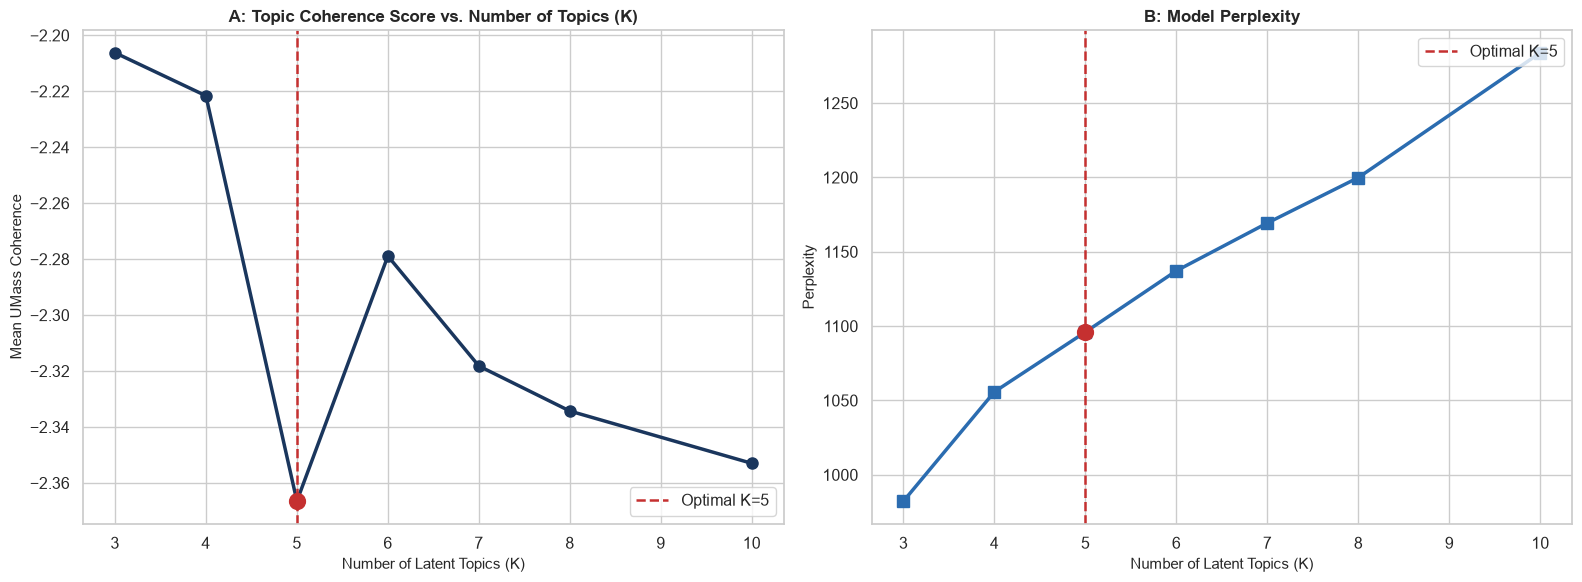

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(df_coherence['K_Topics'], df_coherence['Mean_UMass_Coherence'], marker='o', color='#1A365D', linewidth=2.5, markersize=8)
axes[0].axvline(5, color='#C53030', linestyle='--', linewidth=1.8, label='Optimal K=5')
axes[0].scatter([5], [df_coherence.loc[df_coherence['K_Topics'] == 5, 'Mean_UMass_Coherence'].values[0]], color='#C53030', s=130, zorder=5)
axes[0].set_title("A: Topic Coherence Score vs. Number of Topics (K)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Latent Topics (K)", fontsize=11)
axes[0].set_ylabel("Mean UMass Coherence", fontsize=11)
axes[0].legend(loc='lower right', frameon=True)

axes[1].plot(df_coherence['K_Topics'], df_coherence['Perplexity'], marker='s', color='#2B6CB0', linewidth=2.5, markersize=8)
axes[1].axvline(5, color='#C53030', linestyle='--', linewidth=1.8, label='Optimal K=5')
axes[1].scatter([5], [df_coherence.loc[df_coherence['K_Topics'] == 5, 'Perplexity'].values[0]], color='#C53030', s=130, zorder=5)
axes[1].set_title("B: Model Perplexity", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Latent Topics (K)", fontsize=11)
axes[1].set_ylabel("Perplexity", fontsize=11)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

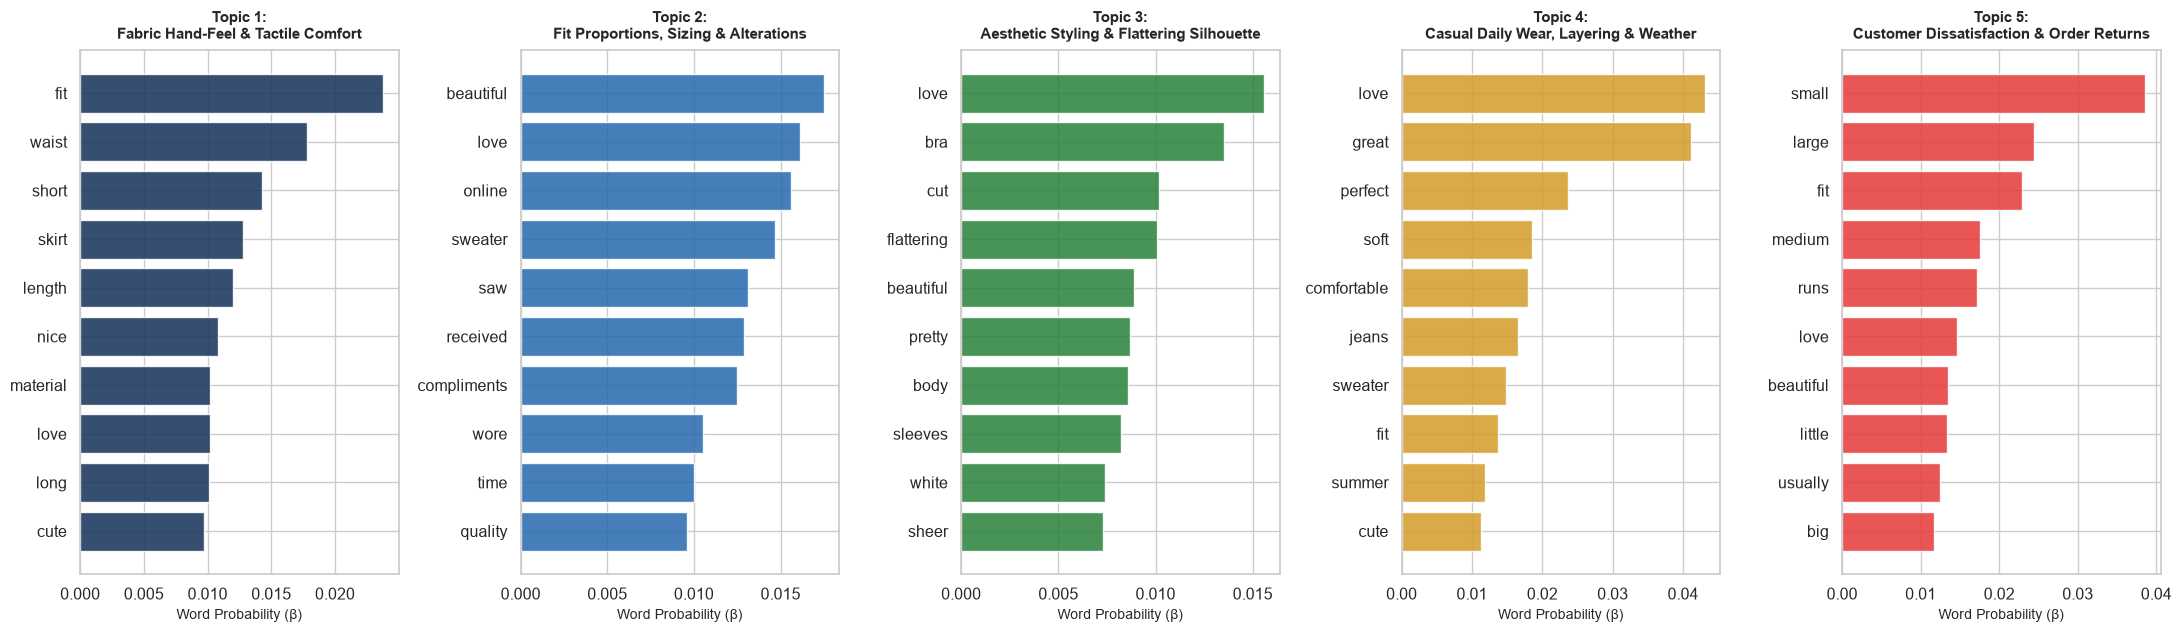

In [5]:
topics_csv = "lda_topic_top_keywords.csv"
if not os.path.exists(topics_csv):
    topics_csv = os.path.join("30-10-2026", "Task 1", "lda_topic_top_keywords.csv")

df_topics = pd.read_csv(topics_csv)

fig, axes = plt.subplots(1, 5, figsize=(22, 6.5))
palette = ['#1A365D', '#2B6CB0', '#2E8540', '#D69E2E', '#E53E3E']
unique_topics = df_topics['Topic_ID'].unique()

for t_id, ax in enumerate(axes):
    sub_df = df_topics[(df_topics['Topic_ID'] == t_id) & (df_topics['Keyword_Rank'] <= 10)].sort_values(by='Probability_Weight', ascending=True)
    ax.barh(sub_df['Keyword'], sub_df['Probability_Weight'], color=palette[t_id], alpha=0.88)
    label_txt = sub_df['Topic_Label'].iloc[0]
    ax.set_title(f"Topic {t_id + 1}:\n{label_txt}", fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel("Word Probability (\u03b2)", fontsize=10)

plt.tight_layout()
plt.show()

In [6]:
lda_5 = LatentDirichletAllocation(
    n_components=5,
    learning_method='online',
    batch_size=512,
    max_iter=6,
    random_state=42,
    n_jobs=1
)
doc_topic_dist = lda_5.fit_transform(dtm)

topic_labels = {
    0: "Fabric Hand-Feel & Tactile Comfort",
    1: "Fit Proportions, Sizing & Alterations",
    2: "Aesthetic Styling & Flattering Silhouette",
    3: "Casual Daily Wear, Layering & Weather",
    4: "Customer Dissatisfaction & Order Returns"
}

df['Dominant_Topic_ID'] = np.argmax(doc_topic_dist, axis=1)
df['Dominant_Topic_Label'] = df['Dominant_Topic_ID'].map(topic_labels)
df['Dominant_Topic_Probability'] = np.round(np.max(doc_topic_dist, axis=1), 4)

display(df[['Full_Review_Text', 'Rating', 'Recommended IND', 'Dominant_Topic_Label', 'Dominant_Topic_Probability']].head(10))

,Full_Review_Text,Rating,Recommended IND,Dominant_Topic_Label,Dominant_Topic_Probability
0,Absolutely wonderful - silky and sexy and comf...,4,1,"Casual Daily Wear, Layering & Weather",0.4657
1,Love this dress! it's sooo pretty. i happene...,5,1,Fabric Hand-Feel & Tactile Comfort,0.4938
2,Some major design flaws I had such high hopes ...,3,0,Customer Dissatisfaction & Order Returns,0.4512
3,"My favorite buy! I love, love, love this jumps...",5,1,"Casual Daily Wear, Layering & Weather",0.6006
4,Flattering shirt This shirt is very flattering...,5,1,"Casual Daily Wear, Layering & Weather",0.9320
5,Not for the very petite I love tracy reese dre...,2,0,Fabric Hand-Feel & Tactile Comfort,0.9159
6,Cagrcoal shimmer fun I aded this in my basket ...,5,1,Fabric Hand-Feel & Tactile Comfort,0.5401
7,"Shimmer, surprisingly goes with lots I ordered...",4,1,"Casual Daily Wear, Layering & Weather",0.3984
8,Flattering I love this dress. i usually get an...,5,1,Customer Dissatisfaction & Order Returns,0.8101
9,"Such a fun dress! I'm 5""5' and 125 lbs. i orde...",5,1,Customer Dissatisfaction & Order Returns,0.6027


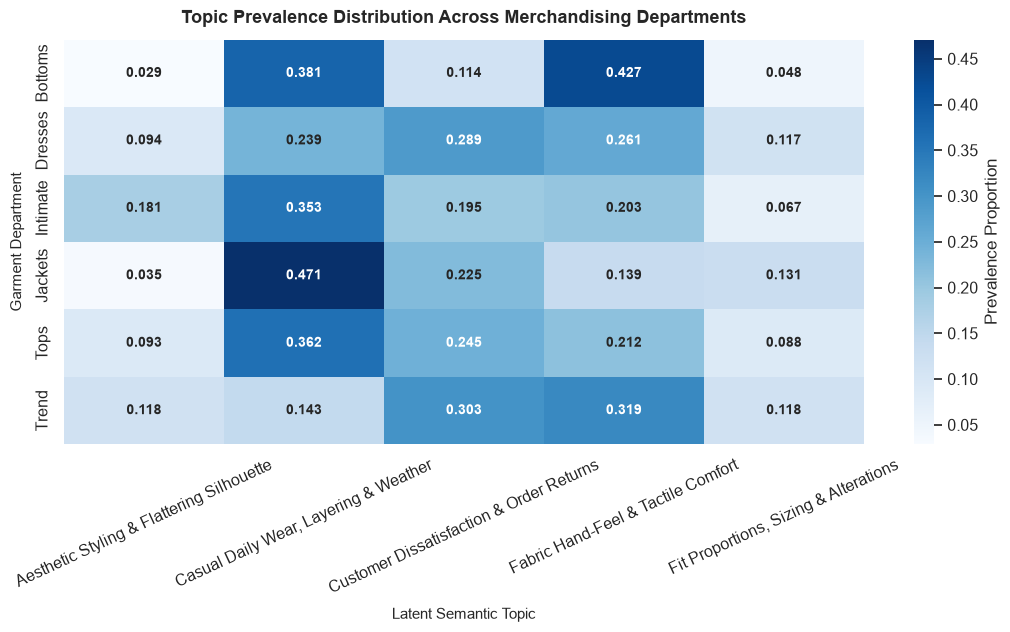

In [7]:
fig, ax = plt.subplots(figsize=(11, 6.5))
dept_topic_crosstab = pd.crosstab(df['Department Name'], df['Dominant_Topic_Label'], normalize='index')
sns.heatmap(dept_topic_crosstab, annot=True, fmt='.3f', cmap='Blues', ax=ax, cbar_kws={'label': 'Prevalence Proportion'}, annot_kws={'size': 10, 'weight': 'bold'})
ax.set_title("Topic Prevalence Distribution Across Merchandising Departments", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Latent Semantic Topic", fontsize=11, labelpad=8)
ax.set_ylabel("Garment Department", fontsize=11, labelpad=8)
ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

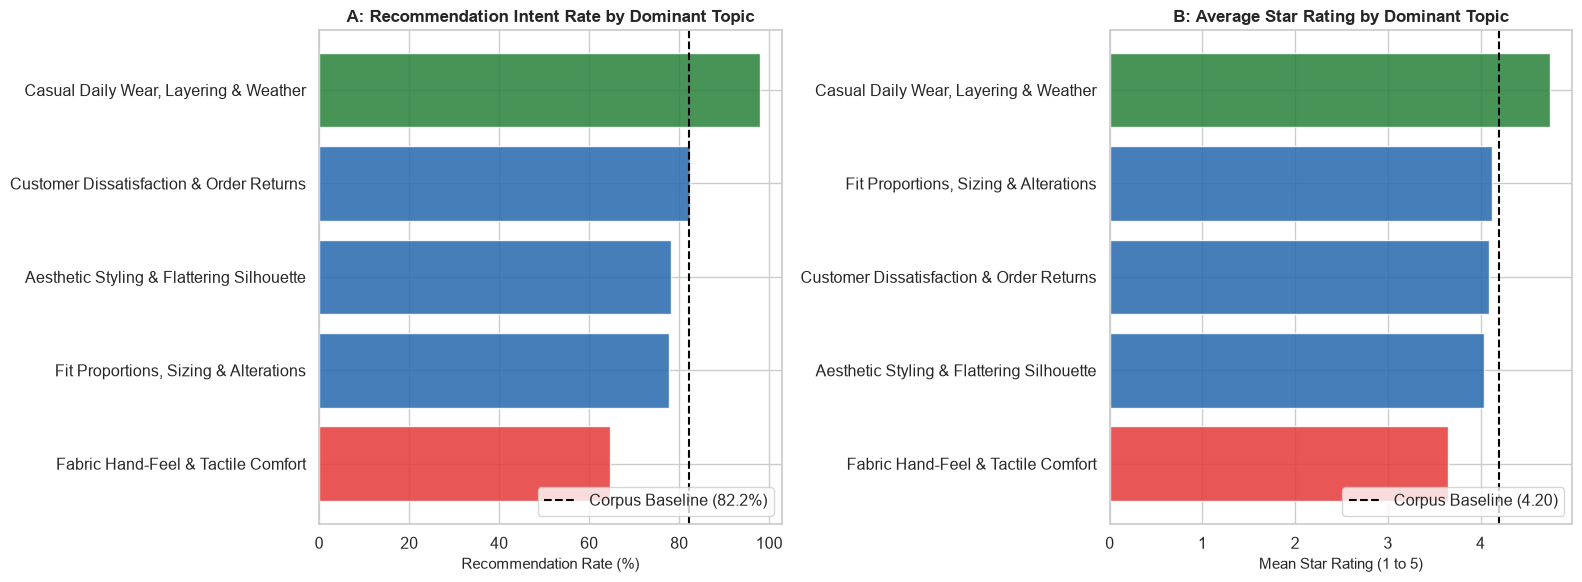

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

topic_rec_rate = df.groupby('Dominant_Topic_Label')['Recommended IND'].mean().reset_index().sort_values(by='Recommended IND', ascending=True)
colors = ['#E53E3E' if r < 0.70 else ('#2E8540' if r > 0.85 else '#2B6CB0') for r in topic_rec_rate['Recommended IND']]

axes[0].barh(topic_rec_rate['Dominant_Topic_Label'], topic_rec_rate['Recommended IND'] * 100, color=colors, alpha=0.88)
axes[0].axvline(df['Recommended IND'].mean() * 100, color='black', linestyle='--', linewidth=1.5, label=f"Corpus Baseline ({df['Recommended IND'].mean()*100:.1f}%)")
axes[0].set_title("A: Recommendation Intent Rate by Dominant Topic", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Recommendation Rate (%)", fontsize=11)
axes[0].legend(loc='lower right', frameon=True)

topic_rating_mean = df.groupby('Dominant_Topic_Label')['Rating'].mean().reset_index().sort_values(by='Rating', ascending=True)
axes[1].barh(topic_rating_mean['Dominant_Topic_Label'], topic_rating_mean['Rating'], color=colors, alpha=0.88)
axes[1].axvline(df['Rating'].mean(), color='black', linestyle='--', linewidth=1.5, label=f"Corpus Baseline ({df['Rating'].mean():.2f})")
axes[1].set_title("B: Average Star Rating by Dominant Topic", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Mean Star Rating (1 to 5)", fontsize=11)
axes[1].legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()